# — Titanic Survival Analysis

### Objective

To analyze Titanic passenger data and identify survival patterns based on age and gender through data cleaning, statistical analysis, and data visualization.

## 1. Import Libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 2. Data Observation

### 2.1 Data Loading

In [2]:
df = pd.read_excel('titanic.xlsx')

### 2.2 Data Inspection

In [3]:
df.head()

,survived,name,sex,age
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000
1,1,"Allison, Master. Hudson Trevor",male,0.9167
2,0,"Allison, Miss. Helen Loraine",female,2.0000
3,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000
4,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000


In [4]:
df.tail()

,survived,name,sex,age
495,1,"Mallet, Mrs. Albert (Antoinette Magnin)",female,24.0
496,0,"Mangiavacchi, Mr. Serafino Emilio",male,NaN
497,0,"Matthews, Mr. William John",male,30.0
498,0,"Maybery, Mr. Frank Hubert",male,40.0
499,0,"McCrae, Mr. Arthur Gordon",male,32.0


In [5]:
df.sample(5, random_state=42)

,survived,name,sex,age
361,1,"Caldwell, Mr. Albert Francis",male,26.0
73,1,"Cleaver, Miss. Alice",female,22.0
374,1,"Clarke, Mrs. Charles V (Ada Maria Winfield)",female,28.0
155,1,"Hays, Mrs. Charles Melville (Clara Jennings Gr...",female,52.0
104,1,"Eustis, Miss. Elizabeth Mussey",female,54.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  500 non-null    int64  
 1   name      500 non-null    str    
 2   sex       500 non-null    str    
 3   age       451 non-null    float64
dtypes: float64(1), int64(1), str(2)
memory usage: 32.6 KB


### 2.3 Data Quality Check

In [7]:
df.shape

(500, 4)

In [8]:
df.isnull().sum()

survived     0
name         0
sex          0
age         49
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(1)

The initial dataset contains 500 rows and 4 columns. The data quality check found 49 missing values in the `age` column and 1 duplicate row. These issues need to be handled before further analysis to improve data quality and ensure more reliable results.

## 3. Data Preprocessing

### 3.1 Duplicate Handling

In [10]:
df = df.drop_duplicates().copy()

In [11]:
df.duplicated().sum()

np.int64(0)

### 3.2 Missing Value Handling

In [12]:
df_age = df.dropna(subset=['age']).copy()

In [30]:
df.isnull().sum()

survived     0
name         0
sex          0
age         49
dtype: int64

In [13]:
df_age.isnull().sum()

survived    0
name        0
sex         0
age         0
dtype: int64

Missing age values were excluded from age-related analyses without removing passengers from the main dataset. As a result, `df` contains 499 passengers, while `df_age` contains 450 passengers with recorded ages.

### 3.3 Age Group Creation

In [14]:
bins = [0, 12, 18, 60, float('inf')]
labels = ['Children', 'Teenagers', 'Adults', 'Elderly']

df_age['age_group'] = pd.cut(
    df_age['age'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

## 4. Statistical Summary and Data Visualization

### 4.1 Passenger Survival Distribution

**Question:** What is the distribution of passengers based on their survival status?

In [15]:
df['survived'].value_counts()

survived
1    269
0    230
Name: count, dtype: int64

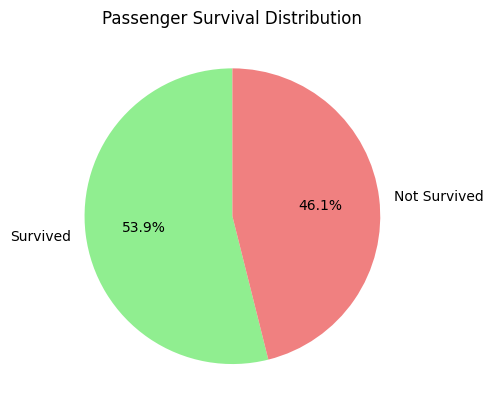

In [16]:
survival_counts = df['survived'].value_counts().reindex([1, 0])

survival_counts.plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    colors=['lightgreen', 'lightcoral'],
    labels=['Survived', 'Not Survived']
)

plt.title('Passenger Survival Distribution')
plt.ylabel('')
plt.show()

Of the 499 passengers, 269 (53.9%) survived, while 230 (46.1%) did not survive. The difference between the two groups was relatively small, with slightly more passengers surviving than not surviving.

### 4.2 Passenger Gender Distribution

**Question:** What is the gender distribution of passengers in the dataset?

In [17]:
df['sex'].value_counts()

sex
male      288
female    211
Name: count, dtype: int64

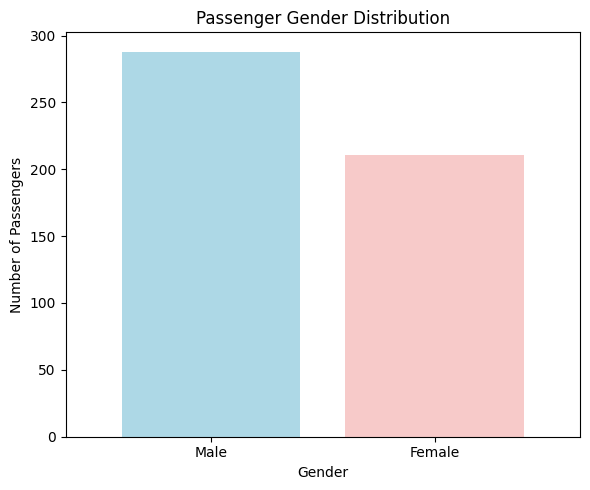

In [18]:
plt.figure(figsize=(6, 5))

sex_counts = df['sex'].value_counts().reindex(['male', 'female'])

sex_counts.plot(
    kind='bar',
    color=['#ADD8E6', '#F7CAC9'],
    width=0.8
)

plt.title('Passenger Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')
plt.xticks(
    ticks=[0, 1],
    labels=['Male', 'Female'],
    rotation=0
)

plt.tight_layout()
plt.show()

Male passengers made up the larger group, with 288 passengers (57.7%), compared to 211 female passengers (42.3%). This means that there were more males than females in the dataset.

### 4.3 Passenger Age Distribution

**Question:** How are passengers distributed across different age groups?

In [19]:
df_age['age'].describe()

count    450.000000
mean      35.877593
std       14.758183
min        0.666700
25%       24.000000
50%       35.000000
75%       47.000000
max       80.000000
Name: age, dtype: float64

In [20]:
df_age['age_group'].value_counts()

age_group
Adults       379
Teenagers     29
Elderly       24
Children      18
Name: count, dtype: int64

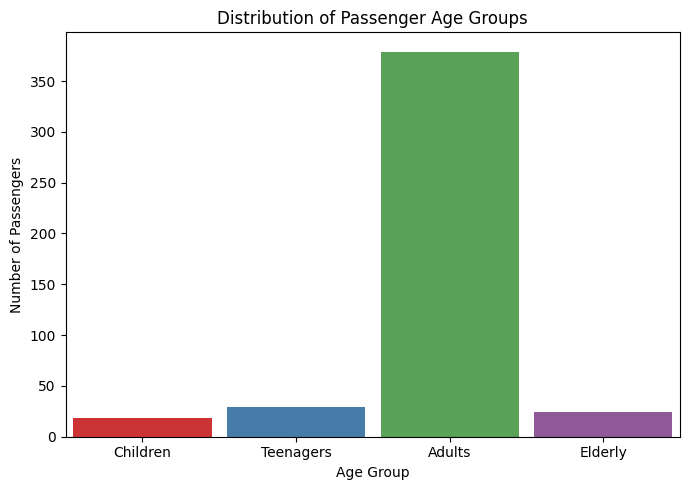

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x='age_group',
    hue='age_group',
    data=df_age,
    palette='Set1',
    legend=False,
    dodge=False,
    width=0.9
)

plt.title('Distribution of Passenger Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Number of Passengers')

plt.tight_layout()
plt.show()

Most passengers with recorded ages were adults, with 379 out of 450 passengers (84.2%). Teenagers made up 6.4%, followed by elderly passengers (5.3%) and children (4.0%). The average age was about 35.9 years, with the youngest passenger under 1 year old and the oldest 80 years old. This shows that adults were the largest age group in the dataset.

*Note: This analysis excludes 49 passengers with missing age values.*

## 5. Final Data Visualization and Analysis Results

### 5.1 Age Group Distribution Based on Passenger Status

**Question:** How is passenger survival related to different age groups?

In [22]:
df_age.groupby('survived')['age_group'].value_counts()

survived  age_group
0         Adults       173
          Elderly       17
          Teenagers     11
          Children       1
1         Adults       206
          Teenagers     18
          Children      17
          Elderly        7
Name: count, dtype: int64

In [23]:
(df_age.groupby('age_group', observed=True)['survived'].mean() * 100).round(2)

age_group
Children     94.44
Teenagers    62.07
Adults       54.35
Elderly      29.17
Name: survived, dtype: float64

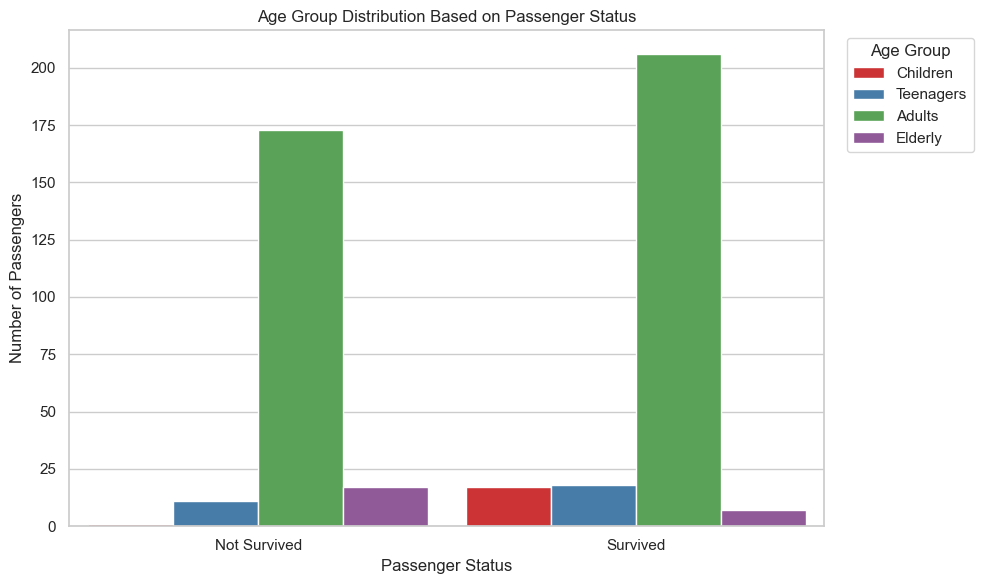

In [24]:
sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.countplot(
    x='survived',
    hue='age_group',
    data=df_age,
    palette='Set1',
    width=0.9
)

plt.title('Age Group Distribution Based on Passenger Status')
plt.xlabel('Passenger Status')
plt.ylabel('Number of Passengers')

plt.xticks(
    ticks=[0, 1],
    labels=['Not Survived', 'Survived']
)

plt.legend(
    title='Age Group',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

Adults had the highest number of survivors, with 206 passengers, and a survival rate of 54.4%. However, children had the highest survival rate at 94.4%, with 17 out of 18 children surviving. Teenagers followed with a survival rate of 62.1%, while elderly passengers had the lowest survival rate at 29.2%. These results show that survival rates were different across age groups, with children having the highest chance of survival among passengers with recorded ages.

### 5.2 Gender Distribution Based on Passenger Status

**Question:** How is passenger survival related to gender?

In [25]:
df.groupby('sex')['survived'].value_counts()

sex     survived
female  1           196
        0            15
male    0           215
        1            73
Name: count, dtype: int64

In [26]:
(df.groupby('sex')['survived'].mean() * 100).round(2)

sex
female    92.89
male      25.35
Name: survived, dtype: float64

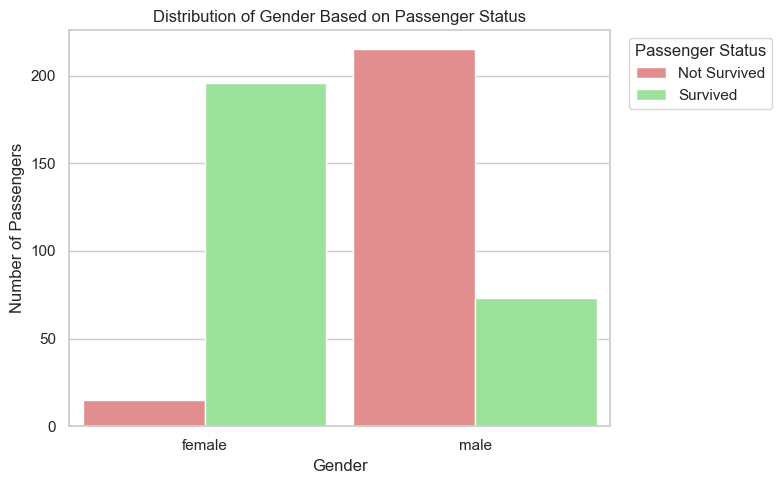

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x='sex',
    hue='survived',
    data=df,
    order=['female', 'male'],
    hue_order=[0, 1],
    palette={0: 'lightcoral', 1: 'lightgreen'},
    width=0.9
)

plt.title('Distribution of Gender Based on Passenger Status')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')

plt.legend(
    title='Passenger Status',
    labels=['Not Survived', 'Survived'],
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

Female passengers had a much higher survival rate than male passengers. About 93% of females survived, compared to only 25% of males. Although there were more male passengers (288) than female passengers (211), most survivors were female. This suggests that gender was an important factor related to passenger survival in this dataset.

### 5.3 Survival Proportions Based on Age Group and Gender

**Question:** How are age group and gender related to passenger survival?

In [28]:
pd.crosstab(
    [df_age['age_group'], df_age['sex']],
    df_age['survived'],
    normalize='index'
).reindex(columns=[0, 1], fill_value=0).rename(
    columns={0: 'Not Survived', 1: 'Survived'}
).round(2)

survived          Not Survived  Survived
age_group sex                           
Children  female          0.12      0.88
          male            0.00      1.00
Teenagers female          0.06      0.94
          male            0.83      0.17
Adults    female          0.07      0.93
          male            0.76      0.24
Elderly   female          0.17      0.83
          male            0.89      0.11

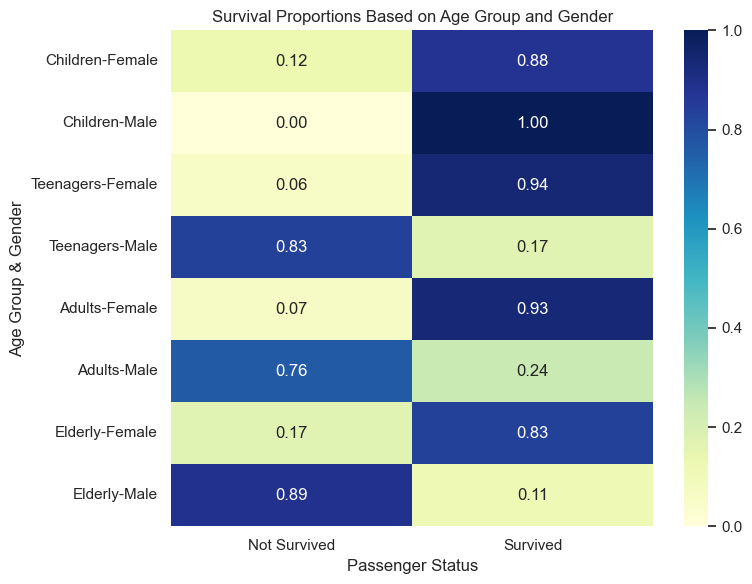

In [29]:
crosstab = pd.crosstab(
    [df_age['age_group'], df_age['sex']],
    df_age['survived'],
    normalize='index'
).reindex(columns=[0, 1], fill_value=0)

crosstab.index = pd.MultiIndex.from_tuples(
    [(str(age), sex.capitalize()) for age, sex in crosstab.index],
    names=['Age Group', 'Gender']
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    crosstab,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f',
    xticklabels=['Not Survived', 'Survived']
)

plt.title('Survival Proportions Based on Age Group and Gender')
plt.xlabel('Passenger Status')
plt.ylabel('Age Group & Gender')
plt.tight_layout()
plt.show()

Survival rates also showed differences when age and gender were analyzed together. Among teenagers, 94% of females survived, compared to only 17% of males. A similar pattern appeared among adults, with 93% of females surviving compared to 24% of males. Elderly females also had a higher survival rate (83%) than elderly males (11%). However, children showed a different pattern. All boys survived (100%), while 88% of girls survived. These results show that survival patterns were different across age groups and genders, although some groups had only a small number of passengers.

## 6. Conclusion

The analysis shows that passenger survival was related to both age and gender. Of the 499 passengers, 269 (53.9%) survived, while 230 (46.1%) did not survive.

Gender showed a clear difference in survival rates. About 93% of female passengers survived, compared to only 25% of male passengers. This shows that female passengers were more likely to survive in this dataset.

Age also showed different survival patterns. Adults had the highest number of survivors, but children had the highest survival rate at 94.4%. Meanwhile, elderly passengers had the lowest survival rate at 29.2%.

When age and gender were analyzed together, female passengers generally had higher survival rates than males across most age groups. However, children showed a different pattern, with all boys surviving in the analyzed sample.

Overall, the findings show that age and gender were related to passenger survival. However, this analysis only identifies patterns and does not prove what caused these differences.

**Limitation:** The age-related analysis only includes 450 passengers with recorded ages, excluding 49 passengers with missing age values. Therefore, the results may not fully represent all passengers in the dataset.